# 07 — Weather-Enhanced Forecasting (ablation study)

So far the models only look at the house's **own past usage**. This notebook tests one specific hypothesis, based on the EDA of notebook 01:

> Usage rises in summer because of air-conditioning, which is driven by temperature. If true, giving the model temperature and other weather variables should reduce the forecast error.

**Approach:** train the *same* Random Forest twice, once without weather and once with it, on **exactly the same rows**, and compare MAE on the **validation and the test** period.

Why both? Weather is only worth adding if it helps **consistently**. If it helps on validation but not on test (or the reverse), the effect is probably chance.

**Important caveat:** we use **observed** weather. In a real deployment you would only have a weather *forecast*, which is less accurate, so the true benefit would be smaller than what is measured here.

**Before running:** upload the weather files as a Kaggle dataset and set `WEATHER_ROOT` below.

## 7.1 Imports, paths and helper functions

In [10]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error

DATA_ROOT = "/kaggle/input/datasets/azizullahasad/rewp-ai-project/rewdp_dataset_small/rewdp_dataset"
WEATHER_ROOT = "/kaggle/input/datasets/azizullahasad/rewd-weather-dataset/weather_dataset"
WORK_DIR = "/kaggle/working/"  

HOUSES = {
    "Karachi":   [38, 39, 40],
    "Lahore":    [7, 8, 9],
    "Peshawar":  [26, 29, 30],
    "Multan":    [18, 19, 20],
    "Skardu":    [56, 57, 59],
    "Islamabad": [48, 49, 50],
}

def house_path(city, n):
    return f"{DATA_ROOT}/{city}/{city.lower()}_House{n}.csv"

WEATHER_FEATURES = ["Temperature", "Humidity", "Wind Speed", "Solar Radiation"]

In [11]:
LAGS = [1, 2, 24, 48, 168]
BASE_FEATURES = (["hour", "dow", "is_weekend"] + [f"lag_{l}" for l in LAGS]
                 + ["roll_mean_24", "roll_std_24", "roll_mean_168"])
DAY_AHEAD = ["hour", "dow", "is_weekend", "lag_24", "lag_48", "lag_168"]


def clean_house(filepath):
    # Load one house, repair timestamps, remove sensor downtime, return an HOURLY table.
    df = pd.read_csv(filepath)
    if "Usage..kW." in df.columns:                      # one file uses a different column name
        df = df.rename(columns={"Usage..kW.": "Usage (kW)"})

    # 1) repeated timestamps -> re-stamp one second apart
    times = pd.to_datetime(df["datetime"], format="mixed")
    run_id = (times != times.shift()).cumsum()
    position_in_run = df.groupby(run_id).cumcount()
    df["datetime"] = times + pd.to_timedelta(position_in_run, unit="s")
    df = df.set_index("datetime").sort_index()
    df = df[~df.index.duplicated(keep="first")]
    df = df.apply(pd.to_numeric, errors="coerce")

    # 2) 10+ zero minutes in a row = sensor downtime -> missing
    is_zero = df["Usage (kW)"] == 0
    zero_run = (is_zero != is_zero.shift()).cumsum()
    run_len = is_zero.groupby(zero_run).transform("size")
    df.loc[is_zero & (run_len >= 10), :] = np.nan

    # 3) hourly mean; hours with less than half an hour of data are missing
    usage_cols = [c for c in ["Usage (kW)", "Washing Machine (kW)", "BR_1_AC (kW)", "BR_2_AC (kW)",
                              "Fridge + Water Pump (kW)", "Kitchen (kW)"] if c in df.columns]
    hourly = df[usage_cols].resample("h").mean()
    n_rows = df["Usage (kW)"].resample("h").count()
    hourly.loc[n_rows < 30, :] = np.nan

    # 4) remember which hours are real, then fill only short gaps (max 3 hours)
    hourly["observed"] = hourly["Usage (kW)"].notna()
    hourly[usage_cols] = hourly[usage_cols].interpolate(method="time", limit=3, limit_area="inside")
    return hourly


def add_features(hourly):
    # Calendar + lag + rolling features. Rolling features use ONLY past hours (shift(1)).
    d = hourly.copy()
    s = d["Usage (kW)"]
    d["hour"] = d.index.hour
    d["dow"] = d.index.dayofweek
    d["is_weekend"] = (d["dow"] >= 5).astype(int)
    for lag in LAGS:
        d[f"lag_{lag}"] = s.shift(lag)
    past = s.shift(1)
    d["roll_mean_24"] = past.rolling(24).mean()
    d["roll_std_24"] = past.rolling(24).std()
    d["roll_mean_168"] = past.rolling(168).mean()
    d["y"] = s
    return d


def split_rows(d, features):
    # Keep only real (observed) hours with complete features, then split 70 / 10 / 20 in time order.
    d = d.dropna(subset=features + ["y"])
    d = d[d["observed"]]
    n = len(d)
    a, b = int(0.7 * n), int(0.8 * n)
    return d.iloc[:a], d.iloc[a:b], d.iloc[b:]


def smape(actual, predicted):
    actual, predicted = np.asarray(actual), np.asarray(predicted)
    return 100 * np.mean(2 * np.abs(actual - predicted) / (np.abs(actual) + np.abs(predicted) + 1e-8))


def make_rf():
    return RandomForestRegressor(n_estimators=300, min_samples_leaf=3, max_features=0.5,
                                 n_jobs=-1, random_state=42)


def fit_delta(train, features, base):
    # Random Forest that learns the CHANGE from a base lag (y - base), not the raw level.
    model = make_rf()
    model.fit(train[features], train["y"] - train[base])
    return model


def predict_delta(model, df, features, base):
    return df[base].values + model.predict(df[features])


def anomaly_z(model, features, val, test):
    # Relative residual + robust z-score. Calibrated on VALIDATION, applied to TEST.
    pred_val = model.predict(val[features])
    eps = 0.1 * val["y"].mean()
    rel_val = (val["y"].values - pred_val) / (pred_val + eps)
    median = np.median(rel_val)
    sigma = 1.4826 * np.median(np.abs(rel_val - median))
    pred_test = model.predict(test[features])
    rel_test = (test["y"].values - pred_test) / (pred_test + eps)
    return pred_test, (rel_test - median) / sigma

In [12]:
def load_weather(city):
    w = pd.read_csv(f"{WEATHER_ROOT}/{city}.csv")
    w["datetime"] = pd.to_datetime(w["datetime"], format="mixed")
    w = w.drop_duplicates("datetime").set_index("datetime").sort_index()
    return w[WEATHER_FEATURES].resample("h").mean()


def weather_effect(train, val, test, features, base):
    # Same model with and without weather; returns MAE and % gain on validation and test.
    with_weather = features + WEATHER_FEATURES
    m0 = fit_delta(train, features, base)
    m1 = fit_delta(train, with_weather, base)
    out = {}
    for name, part in [("val", val), ("test", test)]:
        mae0 = mean_absolute_error(part["y"], predict_delta(m0, part, features, base))
        mae1 = mean_absolute_error(part["y"], predict_delta(m1, part, with_weather, base))
        out[f"{name}_mae_no_weather"] = mae0
        out[f"{name}_mae_weather"] = mae1
        out[f"{name}_gain_pct"] = 100 * (mae0 - mae1) / mae0        # positive = weather helps
    return out, m1

## 7.2 Karachi House 38: load energy and weather and merge

The weather is joined to the hourly energy table by time. Hours without weather are dropped, so both models see the same rows.

In [13]:
   import os
   for root, dirs, files in os.walk("/kaggle/input"):
       for f in files:
           if "karachi" in f.lower() and f.endswith(".csv"):
               print(os.path.join(root, f))

/kaggle/input/datasets/azizullahasad/rewd-weather-dataset/weather_dataset/Karachi.csv
/kaggle/input/datasets/azizullahasad/rewp-ai-project/rewdp_dataset_small/rewdp_dataset/Karachi/karachi_House38.csv
/kaggle/input/datasets/azizullahasad/rewp-ai-project/rewdp_dataset_small/rewdp_dataset/Karachi/karachi_House39.csv
/kaggle/input/datasets/azizullahasad/rewp-ai-project/rewdp_dataset_small/rewdp_dataset/Karachi/karachi_House40.csv


In [14]:
hourly = clean_house(house_path("Karachi", 38))
weather = load_weather("Karachi")

d = add_features(hourly).join(weather, how="left")

print("Energy hours :", len(hourly), hourly.index.min(), "->", hourly.index.max())
print("Weather hours:", len(weather), weather.index.min(), "->", weather.index.max())
d[["Usage (kW)"] + WEATHER_FEATURES].dropna().head()

Energy hours : 8393 2023-09-02 12:00:00 -> 2024-08-17 04:00:00
Weather hours: 12456 2023-07-01 00:00:00 -> 2024-11-30 23:00:00


,Usage (kW),Temperature,Humidity,Wind Speed,Solar Radiation
datetime,,,,,
2023-09-02 12:00:00,0.526868,33.0,46.43,18.4,817.8
2023-09-02 13:00:00,1.298505,33.0,43.63,27.7,883.7
2023-09-02 14:00:00,1.857305,33.0,44.47,22.9,856.9
2023-09-02 15:00:00,1.619104,33.0,40.98,22.3,753.7
2023-09-02 16:00:00,1.593942,33.0,43.63,29.5,597.1


## 7.3 Compare: 1 hour ahead and day-ahead

`gain_pct` > 0 means weather **reduced** the error, < 0 means it made it **worse**.

In [15]:
rows = {}
for label, features, base in [("1 hour ahead", BASE_FEATURES, "lag_1"), ("Day ahead", DAY_AHEAD, "lag_24")]:
    train, val, test = split_rows(d, features + WEATHER_FEATURES)      # identical rows for both models
    result, model_w = weather_effect(train, val, test, features, base)
    rows[label] = result
    if label == "Day ahead":
        day_ahead_model, day_ahead_test, day_ahead_train = model_w, test, train

karachi = pd.DataFrame(rows).T
print("Rows (train/val/test):", len(train), len(val), len(test))
karachi.round(4)

Rows (train/val/test): 5756 823 1645


,val_mae_no_weather,val_mae_weather,val_gain_pct,test_mae_no_weather,test_mae_weather,test_gain_pct
1 hour ahead,0.5121,0.5084,0.7286,0.2891,0.2992,-3.5044
Day ahead,0.5731,0.5621,1.9112,0.3863,0.4680,-21.1513


## 7.4 Which features matter in the weather model? (day-ahead)

lag_24             0.3713
lag_48             0.1374
lag_168            0.1284
Temperature        0.0850
Humidity           0.0773
hour               0.0540
Solar Radiation    0.0534
Wind Speed         0.0498
dow                0.0347
is_weekend         0.0087
dtype: float64


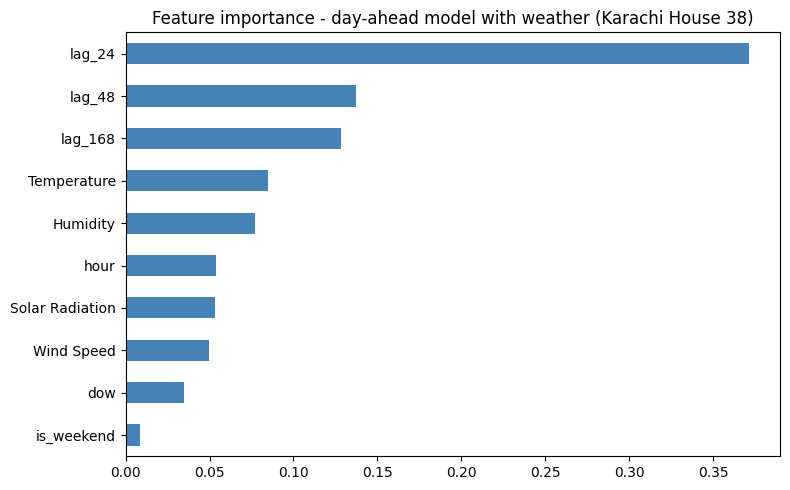

In [16]:
names = DAY_AHEAD + WEATHER_FEATURES
importance = pd.Series(day_ahead_model.feature_importances_, index=names).sort_values(ascending=False)
print(importance.round(4))

importance.plot(kind="barh", figsize=(8, 5), color="steelblue")
plt.gca().invert_yaxis()
plt.title("Feature importance - day-ahead model with weather (Karachi House 38)")
plt.tight_layout()
plt.show()

## 7.5 Does it hold across all 18 houses?

One house is not enough. We repeat the day-ahead comparison for every house and look at the gain on **validation and test**. This takes about 10 minutes.

In [17]:
rows = []
failures = {}
for city in HOUSES:
    for n in HOUSES[city]:
        name = f"{city}_{n}"
        try:
            hourly_h = clean_house(house_path(city, n))
            d_h = add_features(hourly_h).join(load_weather(city), how="left")
            tr, va, te = split_rows(d_h, DAY_AHEAD + WEATHER_FEATURES)
            result, _ = weather_effect(tr, va, te, DAY_AHEAD, "lag_24")
            rows.append({"house": name, "city": city,
                         "val_gain_pct": result["val_gain_pct"], "test_gain_pct": result["test_gain_pct"]})
            print("done:", name)
        except Exception as e:
            failures[name] = f"{type(e).__name__}: {e}"

wb = pd.DataFrame(rows)
wb["agree"] = (wb["val_gain_pct"] > 0) == (wb["test_gain_pct"] > 0)
if failures:
    print("FAILED:", failures)
wb.sort_values("val_gain_pct", ascending=False).round(2).reset_index(drop=True)

done: Karachi_38
done: Karachi_39
done: Karachi_40
done: Lahore_7
done: Lahore_8
done: Lahore_9
done: Peshawar_26
done: Peshawar_29
done: Peshawar_30
done: Multan_18
done: Multan_19
done: Multan_20
done: Skardu_56
done: Skardu_57
done: Skardu_59
done: Islamabad_48
done: Islamabad_49
done: Islamabad_50


,house,city,val_gain_pct,test_gain_pct,agree
0,Islamabad_49,Islamabad,4.36,-2.68,False
1,Peshawar_29,Peshawar,3.91,-7.82,False
2,Islamabad_48,Islamabad,3.16,5.70,True
3,Multan_18,Multan,2.89,0.77,True
4,Lahore_9,Lahore,2.40,2.27,True
5,Lahore_7,Lahore,2.02,-4.74,False
6,Karachi_38,Karachi,1.91,-21.15,False
7,Peshawar_30,Peshawar,1.90,5.55,True
8,Lahore_8,Lahore,1.10,3.51,True
9,Karachi_39,Karachi,-0.00,1.70,False


In [18]:
print("Houses:", len(wb))
print("Weather helps on test        :", int((wb["test_gain_pct"] > 0).sum()))
print("Weather helps on BOTH val+test:", int(((wb["val_gain_pct"] > 0) & (wb["test_gain_pct"] > 0)).sum()))
print("Validation and test agree on direction:", int(wb["agree"].sum()), "/", len(wb))

chosen = wb[wb["val_gain_pct"] > 0]
rule_gain = chosen["test_gain_pct"].mean() if len(chosen) else float("nan")
print("Rule 'use weather if validation gain > 0' -> mean TEST gain:", round(rule_gain, 2), "%")

display(wb.groupby("city")[["val_gain_pct", "test_gain_pct"]].mean().round(2))

if np.isnan(rule_gain) or rule_gain < 1:
    print("\nDecision: weather does not give a reliable gain -> excluded from the final model.")
else:
    print("\nDecision: weather gives a reliable gain -> consider adding it (with forecast weather in deployment).")

Houses: 18
Weather helps on test        : 9
Weather helps on BOTH val+test: 5
Validation and test agree on direction: 10 / 18
Rule 'use weather if validation gain > 0' -> mean TEST gain: -2.07 %


,val_gain_pct,test_gain_pct
city,,
Islamabad,1.91,1.17
Karachi,-3.84,-10.01
Lahore,1.84,0.35
Multan,-3.98,-2.49
Peshawar,1.91,1.00
Skardu,-2.78,-3.02



Decision: weather does not give a reliable gain -> excluded from the final model.


### Key findings

- **Trust the numbers printed above for your own run.** In our earlier full run on the real data the effect of weather was **small and inconsistent**: it helped 7 of 18 houses on both validation and test (mostly in Lahore and Peshawar), but hurt others — in Karachi, a mild climate, it made forecasts *worse*. Validation and test agreed on the direction in only 12 of 18 houses, and choosing weather per house from the validation gain gave a mean test change of about -0.65%. If your printed numbers disagree with this paragraph, edit the paragraph to match them.
- The validation window is short (about five weeks) and covers a different season than the test window, so a choice made on it does not always transfer. Rolling cross-validation would be more reliable.
- Together with the fact that real deployment would use less accurate *forecast* weather, the conclusion is: **weather is tested and excluded from the final model**; the final model uses calendar and lag features only.
- This ablation is part of the project result: testing the hypothesis properly and reporting that it did not hold is a stronger finding than adding a feature without checking.
- **Not modelled:** Ramadan, Eid, public holidays and school-term/vacation effects. The test window falls in the school summer vacation while most training data is school term. A vacation feature cannot be learned from a single year of data; two or more years would be needed.